In [7]:
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from dotenv import load_dotenv
import os

In [ ]:
# load env variables
load_dotenv()

GEMINI_API_KEY=os.getenv('GOOGLE_API_KEY')

### Define LLM

In [9]:
model = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    google_api_key=GEMINI_API_KEY,
    temperature=1.0,  
    max_retries=2,
)

### Define a State

In [12]:
class LLMState(TypedDict):
    question: str
    answer: str

### Creating Node

In [18]:
def llmqa(state: LLMState) -> LLMState:
    question = state['question']
    prompt = f"Asnwer the following question {question}"

    # ask the llm 
    answer = model.invoke(prompt).content

    #update state with answer from llm
    state['answer'] = answer
    return state

### Define and Compile Graph

In [20]:
graph = StateGraph(LLMState)

# add nodes
graph.add_node('llmqa',llmqa)

# add edges
graph.add_edge(START,'llmqa')
graph.add_edge('llmqa',END)

workflow = graph.compile()

### Execute Graph

In [21]:
initial_state = {'question':'who is the creator of python?'}
final_state = workflow.invoke(initial_state)

print(final_state['answer'])

/home/med/miniconda3/envs/langagent/lib/python3.11/site-packages/langchain_google_genai/chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[{'type': 'text', 'text': 'The creator of Python is **Guido van Rossum**. He began working on the language in the late 1980s at Centrum Wiskunde & Informatica (CWI) in the Netherlands, and the first release of Python came out in 1991.', 'extras': {'signature': 'EmAKXgFpFH0T/G8fsiu10GcTDetr0ywvkg+0GMnwKgDhln6UZVhConzlxLIwfpXdvr9s/2Ybs6RLqsK1CrBnMVtXU35O1JLObxht8OFQUK9xnY3k2cY8349wf31Dl3tjOoc='}}]


### Visualize Graph

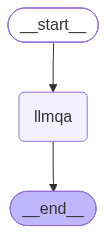

In [23]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())